# 04 · Distributions (Wilke ch. 8–9)

Chapters 8 & 9 (Wilke, Fundamentals of Data Visualization): distributions.

Run from `analysis/deliverable2/` (same code as `04_distributions.py`).
Reads the raw F1DB v2026.15.1 CSVs in ../data/raw/ and writes PNGs to figures/,
named ch8_*.png and ch9_*.png so they don't collide with the Lecture 4-5 figures.
Each figure is sized in "slide pixels" (figsize = px / 100) and saved at
dpi=200, so it renders sharp at 2x on a 1920x1080 slide.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

HERE = Path.cwd()  # run from analysis/deliverable2/
DATA = HERE.parent / "data" / "raw"
OUT = HERE / "figures"
OUT.mkdir(exist_ok=True)

BLUE, ORANGE, INK, MUTED, AXIS, GRID = "#2F6DB5", "#D9822B", "#1B2433", "#4A5568", "#8A93A0", "#E6E2D8"
plt.rcParams.update({
    "font.family": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 17, "axes.labelsize": 18, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1,
    "figure.facecolor": "white", "axes.facecolor": "white",
})

CODES = {"australia": "AUS", "china": "CHN", "japan": "JPN", "miami": "MIA", "canada": "CAN",
         "monaco": "MON", "barcelona-catalunya": "BCN", "austria": "AUT", "great-britain": "GBR",
         "belgium": "BEL", "hungary": "HUN", "netherlands": "NED", "italy": "ITA", "spain": "ESP",
         "azerbaijan": "AZE"}


def fig(w_px, h_px):
    return plt.subplots(figsize=(w_px / 100, h_px / 100))


CH8 = {"ecdf_pitstops", "starts_linear", "starts_log", "loglog_careers", "qq_pitstops", "qq_log_starts"}


def save(f, name):
    f.tight_layout()
    f.savefig(OUT / f"{'ch8' if name in CH8 else 'ch9'}_{name}.png", dpi=200)
    plt.close(f)

## Data
Load the raw F1DB CSVs: 2026 pit stops and driver career totals.

In [2]:
# ---------- data ----------
races = pd.read_csv(DATA / "f1db-races.csv")
ps = pd.read_csv(DATA / "f1db-races-pit-stops.csv")
ps["sec"] = ps.timeMillis / 1000
p26 = ps[ps.year == 2026].merge(races[["id", "grandPrixId"]], left_on="raceId", right_on="id")
p26["gp"] = p26.grandPrixId.map(CODES)
order = (p26[["round", "gp"]].drop_duplicates().sort_values("round").gp.tolist())
groups = [p26.loc[p26.gp == g, "sec"].values for g in order]
t = np.sort(p26.sec.values)
n = len(t)

drivers = pd.read_csv(DATA / "f1db-drivers.csv")
starts = drivers.loc[drivers.totalRaceStarts > 0, "totalRaceStarts"].values
points = drivers.loc[drivers.totalPoints > 0, "totalPoints"].values

## Chapter 8: ECDFs and Q-Q plots
ECDF of pit lane times, linear vs log density of career starts, log–log descending ECDF, and Q-Q plots against a normal reference.

In [3]:
# ---------- Ch 8 ----------
# ECDF of all 2026 pit stops
f, ax = fig(760, 480)
ax.step(t, np.arange(1, n + 1) / n, where="post", color=BLUE, lw=2.5)
med = np.median(t)
ax.axhline(0.5, color=AXIS, ls="--", lw=1.5)
ax.axvline(med, color=AXIS, ls="--", lw=1.5)
ax.set_xlabel("pit lane time (s)")
ax.set_ylabel("cumulative fraction")
ax.set_ylim(0, 1.02)
save(f, "ecdf_pitstops")

# Linear vs log density of career race starts
for name, logx in [("starts_linear", False), ("starts_log", True)]:
    f, ax = fig(800, 500)
    x = np.log10(starts) if logx else starts
    kde = stats.gaussian_kde(x)
    grid = np.linspace(x.min(), x.max(), 400)
    ax.fill_between(grid, kde(grid), color=BLUE, alpha=0.3, lw=0)
    ax.plot(grid, kde(grid), color=BLUE, lw=2.5)
    if logx:
        ax.set_xticks([0, 1, 2], ["1", "10", "100"])
        ax.set_xlabel("career race starts (log scale)")
    else:
        ax.set_xlabel("career race starts")
    ax.set_ylabel("density")
    ax.set_yticks([])
    save(f, name)

# Descending ECDF on log-log axes
f, ax = fig(760, 480)
for vals, c, lab in [(starts, BLUE, "career race starts"), (points, ORANGE, "career points")]:
    v = np.sort(vals)
    frac = 1 - np.arange(len(v)) / len(v)          # fraction of drivers >= v
    ax.loglog(v, frac, ls="none", marker="o", ms=5, color=c, alpha=0.7, label=lab)
ax.set_xlabel("value (log scale)")
ax.set_ylabel("fraction of drivers ≥ value")
ax.legend(frameon=False, loc="lower left")
save(f, "loglog_careers")

# Q-Q: pit stops vs normal with the same mean and SD
f, ax = fig(760, 480)
theo = stats.norm.ppf((np.arange(1, n + 1) - 0.5) / n, loc=t.mean(), scale=t.std(ddof=1))
ax.plot([theo.min(), t.max()], [theo.min(), t.max()], color=MUTED, lw=2)
ax.plot(theo, t, ls="none", marker="o", ms=6, color=BLUE, alpha=0.6)
ax.set_xlabel("theoretical normal quantile (s)")
ax.set_ylabel("observed pit lane time (s)")
save(f, "qq_pitstops")

# Q-Q: log10 career starts vs normal
f, ax = fig(640, 380)
ls_ = np.sort(np.log10(starts))
m = len(ls_)
theo = stats.norm.ppf((np.arange(1, m + 1) - 0.5) / m, loc=ls_.mean(), scale=ls_.std(ddof=1))
lo, hi = min(theo.min(), ls_.min()), max(theo.max(), ls_.max())
ax.plot([lo, hi], [lo, hi], color=MUTED, lw=2)
ax.plot(theo, ls_, ls="none", marker="o", ms=5, color=ORANGE, alpha=0.6)
ax.set_xlabel("theoretical normal quantile")
ax.set_ylabel("log10(career starts)")
save(f, "qq_log_starts")

## Chapter 9: many distributions at once
Error bars (the plot to avoid), boxplots, violins, strip/jitter/sina, and ridgelines. Every race chart is sorted by median pit lane time, fastest at the top.

In [4]:
# ---------- Ch 9 ----------
# Categories go on the y axis (readable horizontal labels), first race at the top.
NAMES = {"AUS": "Australia", "CHN": "China", "JPN": "Japan", "MIA": "Miami", "CAN": "Canada",
         "MON": "Monaco", "BCN": "Barcelona", "AUT": "Austria", "GBR": "Great Britain",
         "BEL": "Belgium", "HUN": "Hungary", "NED": "Netherlands", "ITA": "Italy", "ESP": "Spain",
         "AZE": "Azerbaijan"}
# Sort every race chart the same way: by median pit lane time, fastest race at the top
rank = np.argsort([np.median(g) for g in groups])
order = [order[i] for i in rank]
groups = [groups[i] for i in rank]
labels = [NAMES[g] for g in order]
ys = np.arange(len(order))[::-1]


def cat_axis(ax, ys, labels):
    ax.set_yticks(ys, labels)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    ax.set_xlabel("pit lane time (s)")


# Mean +/- 2 SD (the plot to avoid)
f, ax = fig(760, 600)
means = [g.mean() for g in groups]
sds = [g.std(ddof=1) for g in groups]
ax.errorbar(means, ys, xerr=2 * np.array(sds), fmt="o", color=INK, ms=7, capsize=5, lw=2)
cat_axis(ax, ys, labels)
save(f, "errorbars")

# Boxplots
f, ax = fig(860, 600)
ax.boxplot(groups, positions=ys, widths=0.6, patch_artist=True, orientation="horizontal",
           boxprops=dict(facecolor="#C9D9EE", edgecolor=INK, lw=1.5),
           medianprops=dict(color=INK, lw=3), whiskerprops=dict(color=INK, lw=1.5),
           capprops=dict(color=INK, lw=1.5),
           flierprops=dict(marker="o", markerfacecolor=ORANGE, markeredgecolor="white", ms=8))
cat_axis(ax, ys, labels)
save(f, "boxplots")

# Violins
f, ax = fig(860, 600)
vp = ax.violinplot(groups, positions=ys, widths=1.15, showextrema=False, bw_method=0.25,  # wide: the bumps are easier to see
                   orientation="horizontal")
for b in vp["bodies"]:
    b.set_facecolor(BLUE); b.set_edgecolor(INK); b.set_linewidth(1); b.set_alpha(0.8)
ax.scatter([np.median(g) for g in groups], ys, color=INK, s=30, zorder=3)
cat_axis(ax, ys, labels)
save(f, "violins")

# Strip / jitter / sina for four races
pick = [g for g in order if g in {"AUS", "GBR", "NED", "ESP"}]  # same order as the other race charts
sub = [p26.loc[p26.gp == g, "sec"].values for g in pick]
pys = np.arange(len(pick))[::-1]
rng = np.random.default_rng(7)
for mode in ["strip", "jitter", "sina"]:
    f, ax = fig(520, 500)
    for y0, g in zip(pys, sub):
        if mode == "strip":
            dy = np.zeros(len(g))
        elif mode == "jitter":
            dy = rng.uniform(-0.3, 0.3, len(g))
        else:
            kde = stats.gaussian_kde(g, bw_method=0.35)
            d = kde(g) / kde(g).max()
            dy = rng.uniform(-1, 1, len(g)) * 0.38 * d
        ax.scatter(g, y0 + dy, s=34, color=BLUE, alpha=0.5, edgecolors="none")
    cat_axis(ax, pys, [NAMES[p] for p in pick])
    ax.set_ylim(-0.6, len(pick) - 0.4)
    save(f, f"points_{mode}")

# Ridgeline of the 15 races (first race at top)
def ridgeline(groups, labels, w_px, h_px, xlim, xlabel, name, step=1.0, scale=1.3, highlight=None, bw=0.35,
              label_every=1, trim=None):
    f, ax = fig(w_px, h_px)
    grid = np.linspace(*xlim, 500)
    k = len(groups)
    for i, (g, lab) in enumerate(zip(groups, labels)):
        base = (k - 1 - i) * step
        gx = grid
        dens = stats.gaussian_kde(g, bw_method=bw)(gx)
        dens = dens / dens.max()
        if trim:  # like ggridges' rel_min_height: drop the thin tails below trim x peak height
            keep = np.flatnonzero(dens >= trim)
            gx, dens = gx[keep[0]:keep[-1] + 1], dens[keep[0]:keep[-1] + 1]
        dens = dens * scale
        c = ORANGE if highlight and lab in highlight else BLUE
        ax.fill_between(gx, base, base + dens, color=c, alpha=0.85, lw=0, zorder=10 + 2 * i)
        ax.plot(gx, base + dens, color="white", lw=1.5, zorder=11 + 2 * i)
    ax.set_yticks([(k - 1 - i) * step for i in range(0, k, label_every)], labels[::label_every])
    ax.set_xlim(*xlim)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
    save(f, name)

by_median = np.argsort([np.median(g) for g in groups])  # fastest race at the top
ridgeline([groups[i] for i in by_median], [labels[i] for i in by_median], 1200, 632, (15, 45),
          "pit lane time (s)", "ridgeline_races", highlight={"Australia", "Great Britain"})

# Ridgeline by season: driver age at each race start, 1950-2026
rr = pd.read_csv(DATA / "f1db-races-race-results.csv", low_memory=False, usecols=["raceId", "year", "driverId"])
dob = drivers.set_index("id").dateOfBirth
ages = rr.merge(races[["id", "date"]], left_on="raceId", right_on="id")
ages["age"] = (pd.to_datetime(ages.date) - pd.to_datetime(ages.driverId.map(dob))).dt.days / 365.25
ages = ages.dropna(subset=["age"]).sort_values("date").drop_duplicates(["year", "driverId"])  # one age per driver per season
ages["period"] = (ages.year // 5) * 5
periods = sorted(ages.period.unique())
ag = [ages.loc[ages.period == p, "age"].values for p in periods]
plabels = [f"{p}–{str(min(p + 4, 2026))[2:]}" for p in periods]
ridgeline(ag, plabels, 1100, 640, (16, 52), "driver age at first start of the season (years)", "ridgeline_years",
          step=1.0, scale=1.8, bw=0.4, label_every=1, trim=0.03, highlight={plabels[0], plabels[-1]})

# Cover art on the dark slide background: one chart from each chapter
DARK, LIGHT, SOFTTXT = "#1B2433", "#F6F4EE", "#C9D3E0"
with plt.rc_context({"figure.facecolor": DARK, "axes.facecolor": DARK, "axes.edgecolor": "#4A5A70",
                     "xtick.color": SOFTTXT, "ytick.color": SOFTTXT, "axes.labelcolor": SOFTTXT, "grid.color": "#2E3A4F"}):
    f, (a1, a2) = plt.subplots(2, 1, figsize=(7.0, 6.6), gridspec_kw={"height_ratios": [1, 1.25], "hspace": 0.55})
    a1.step(t, np.arange(1, n + 1) / n, where="post", color="#8FB4E3", lw=2.5)
    a1.set_title("Ch 8 · ECDF of 2026 pit stops", loc="left", color=LIGHT, fontsize=17, fontweight="bold", pad=10)
    a1.set_xlabel("pit lane time (s)"); a1.set_yticks([0, 0.5, 1])
    sel = list(range(0, len(ag), 3))
    grid = np.linspace(16, 52, 400)
    for j, i in enumerate(sel):
        base = (len(sel) - 1 - j) * 1.0
        dn = stats.gaussian_kde(ag[i], bw_method=0.4)(grid); dn = dn / dn.max() * 1.7
        keep = np.flatnonzero(dn >= 0.03 * 1.7); gx, dn = grid[keep[0]:keep[-1] + 1], dn[keep[0]:keep[-1] + 1]
        a2.fill_between(gx, base, base + dn, color=ORANGE if j in (0, len(sel) - 1) else "#2F6DB5", alpha=0.9, lw=0, zorder=10 + 2 * j)
        a2.plot(gx, base + dn, color=DARK, lw=1.5, zorder=11 + 2 * j)
    a2.set_yticks([(len(sel) - 1 - j) * 1.0 for j in range(len(sel))], [plabels[i][:4] + "s" if False else plabels[i] for i in sel])
    a2.set_title("Ch 9 · Driver age by era, as a ridgeline", loc="left", color=LIGHT, fontsize=17, fontweight="bold", pad=10)
    a2.set_xlabel("driver age (years)"); a2.grid(axis="y", visible=False); a2.tick_params(axis="y", length=0)
    a2.spines["left"].set_visible(False)
    f.savefig(OUT / "deck_cover_art.png", dpi=200, bbox_inches="tight", facecolor=DARK)
    plt.close(f)

## Numbers quoted on the slides

In [5]:
# ---------- numbers quoted on the slides ----------
print("pit stops:", n, "median", round(med, 2), "q25", round(np.quantile(t, .25), 2),
      "q80", round(np.quantile(t, .8), 2), "max", t.max())
print("share <= 20 s:", round((t <= 20).mean(), 3), "share > 30 s:", round((t > 30).mean(), 3))
top = drivers.sort_values("totalRaceStarts").iloc[-1]
print("starts: drivers", len(starts), "median", np.median(drivers.totalRaceStarts), "max", top.totalRaceStarts, top.fullName)
topp = drivers.sort_values("totalPoints").iloc[-1]
print("points: drivers>0", len(points), "median all", np.median(drivers.totalPoints), "max", topp.totalPoints, topp.fullName)
print("skew pit", round(stats.skew(t), 2), "| shapiro log starts p", stats.shapiro(np.log10(starts)).pvalue)
for g, arr in zip(order, groups):
    print(g, len(arr), "median", round(np.median(arr), 2), "IQR", np.round(np.quantile(arr, [.25, .75]), 2),
          "max", round(arr.max(), 1))
print("median by era: <=2009", ps.loc[ps.year.between(1994, 2009), "sec"].median(),
      ">=2010", ps.loc[ps.year >= 2010, "sec"].median())
print("age medians:", {l: round(float(np.median(a)), 1) for l, a in zip(plabels, ag)})
print("age n:", {l: len(a) for l, a in zip(plabels, ag)})

pit stops: 469 median 23.32 q25 21.75 q80 28.74 max 47.067
share <= 20 s: 0.126 share > 30 s: 0.147
starts: drivers 792 median 4.0 max 441 Fernando Alonso Díaz
points: drivers>0 357 median all 0.0 max 5217.5 Lewis Carl Davidson Hamilton
skew pit 1.37 | shapiro log starts p 5.925573763371496e-19
NED 42 median 18.07 IQR [17.78 18.7 ] max 20.3
AUS 30 median 18.93 IQR [18.3  22.58] max 36.7
AZE 20 median 21.04 IQR [20.71 21.96] max 23.7
AUT 41 median 21.56 IQR [21.27 21.88] max 28.7
HUN 44 median 22.02 IQR [21.75 22.35] max 28.7
BCN 47 median 22.7 IQR [22.26 23.27] max 26.4
MIA 21 median 23.16 IQR [22.63 23.6 ] max 33.7
CHN 19 median 23.39 IQR [23.08 25.87] max 47.1
JPN 26 median 24.23 IQR [23.46 24.63] max 27.3
BEL 28 median 24.74 IQR [23.27 27.79] max 34.8
CAN 30 median 25.15 IQR [24.75 28.24] max 36.6
MON 28 median 25.59 IQR [24.81 26.79] max 35.3
ITA 18 median 26.39 IQR [24.93 28.46] max 35.3
GBR 50 median 29.55 IQR [28.85 32.01] max 46.2
ESP 25 median 31.48 IQR [31.16 32.  ] max 46.4


## Figures

ch8_ecdf_pitstops.png


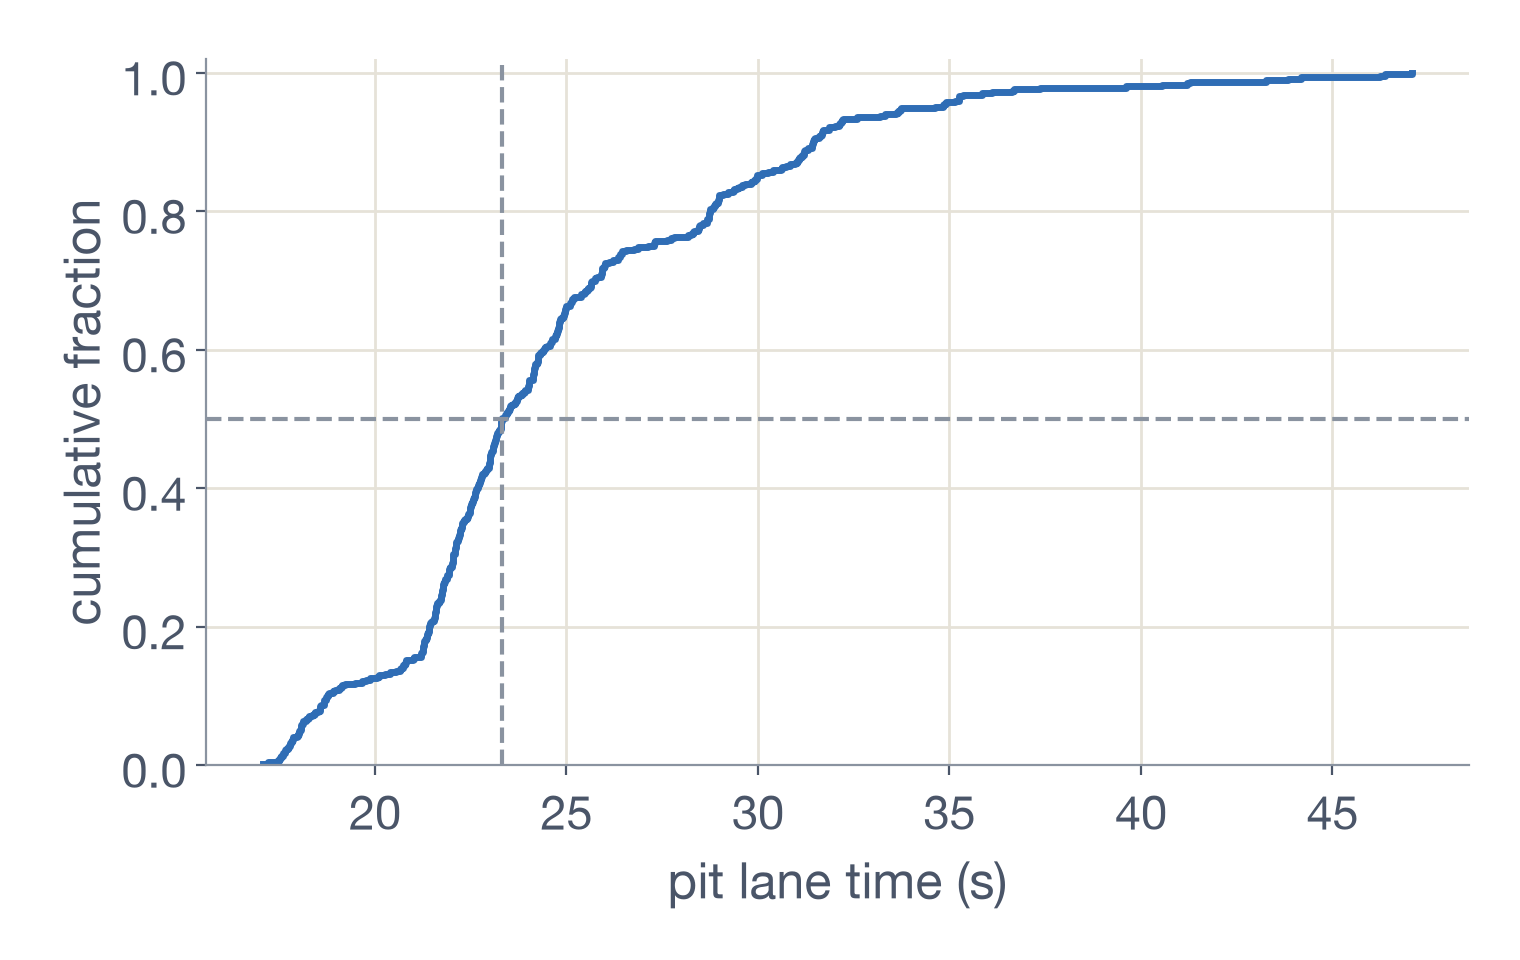

ch8_loglog_careers.png


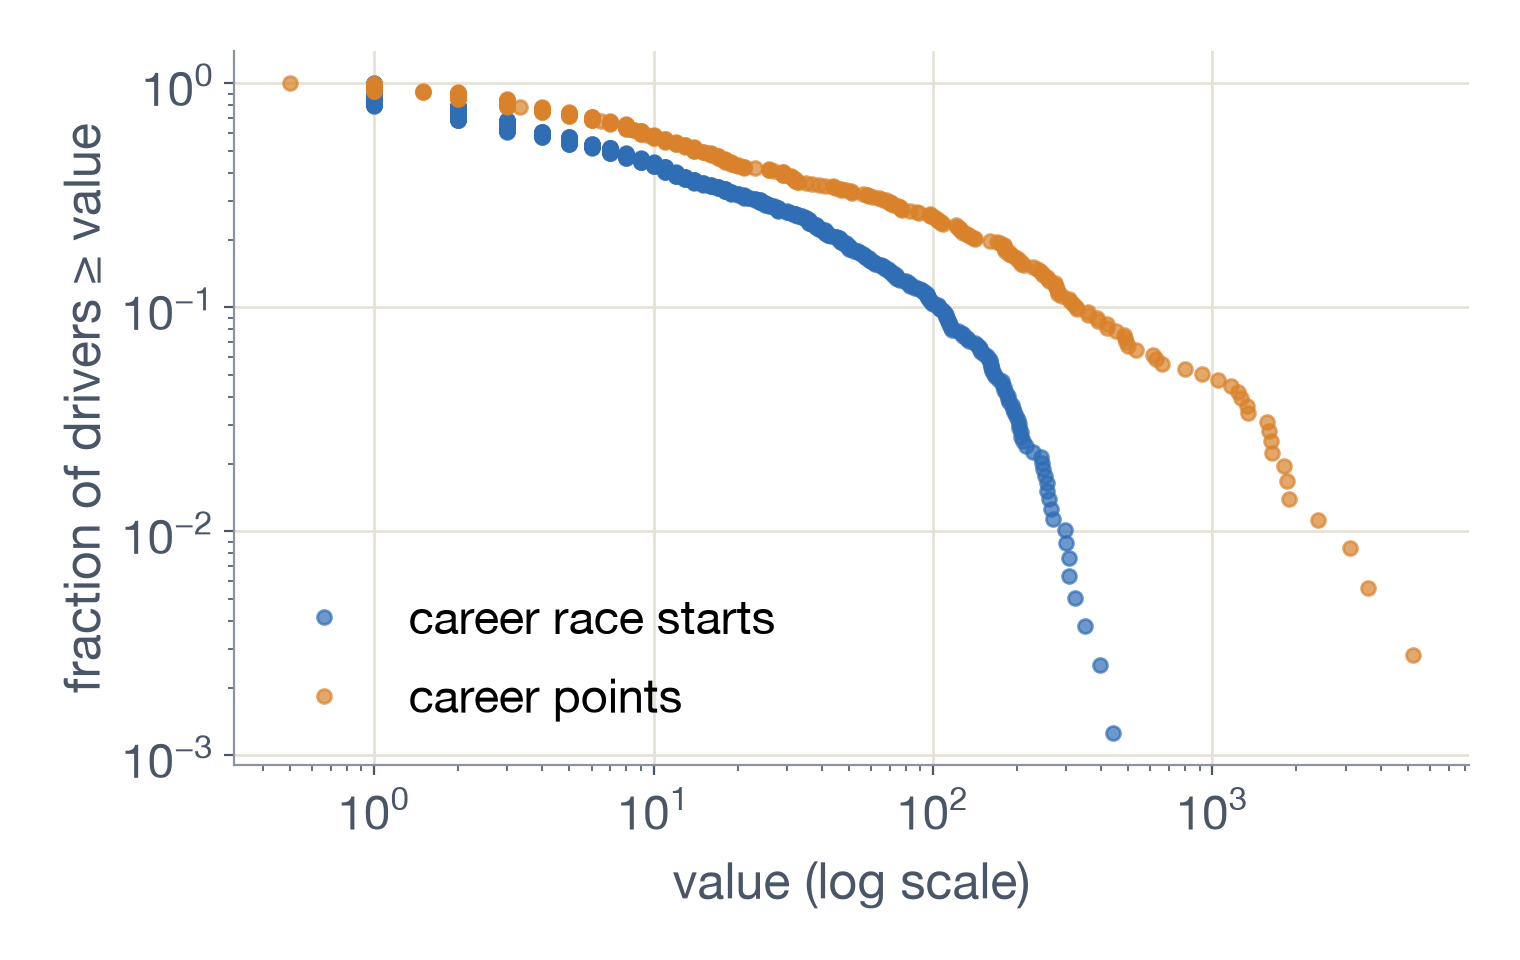

ch8_qq_log_starts.png


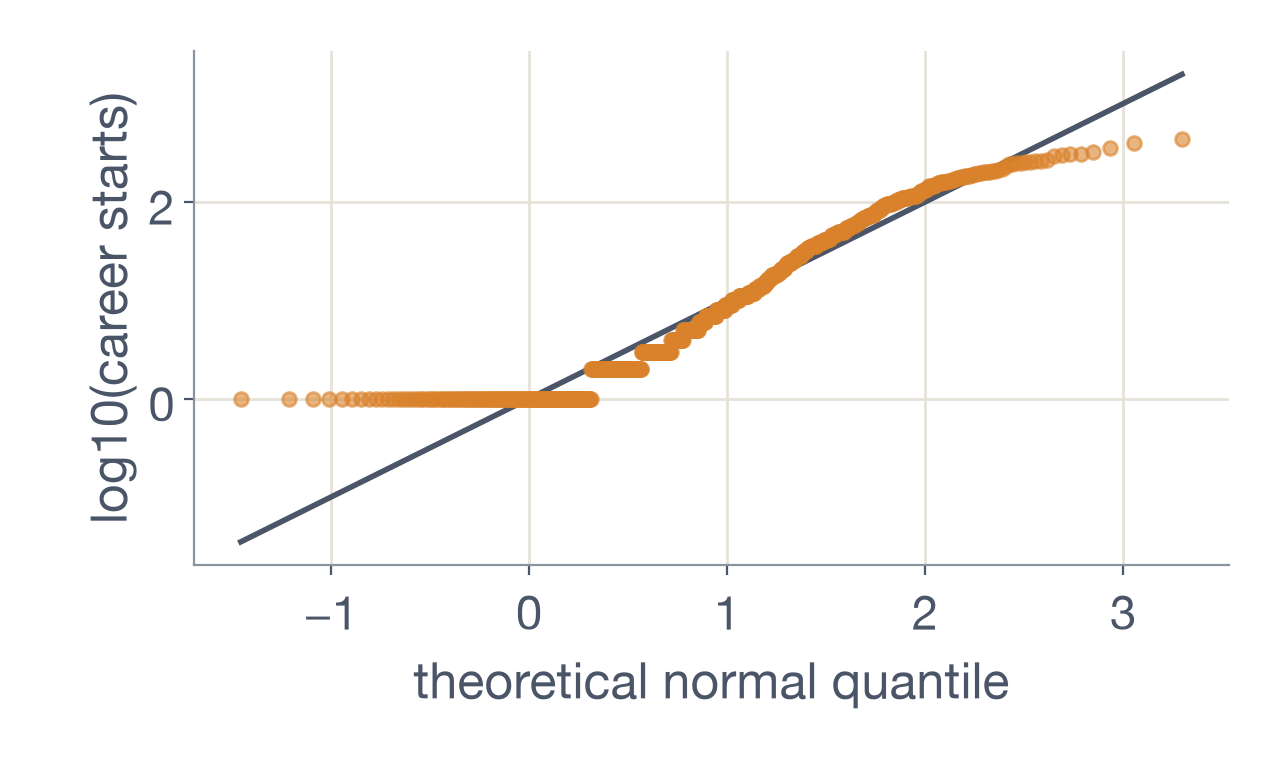

ch8_qq_pitstops.png


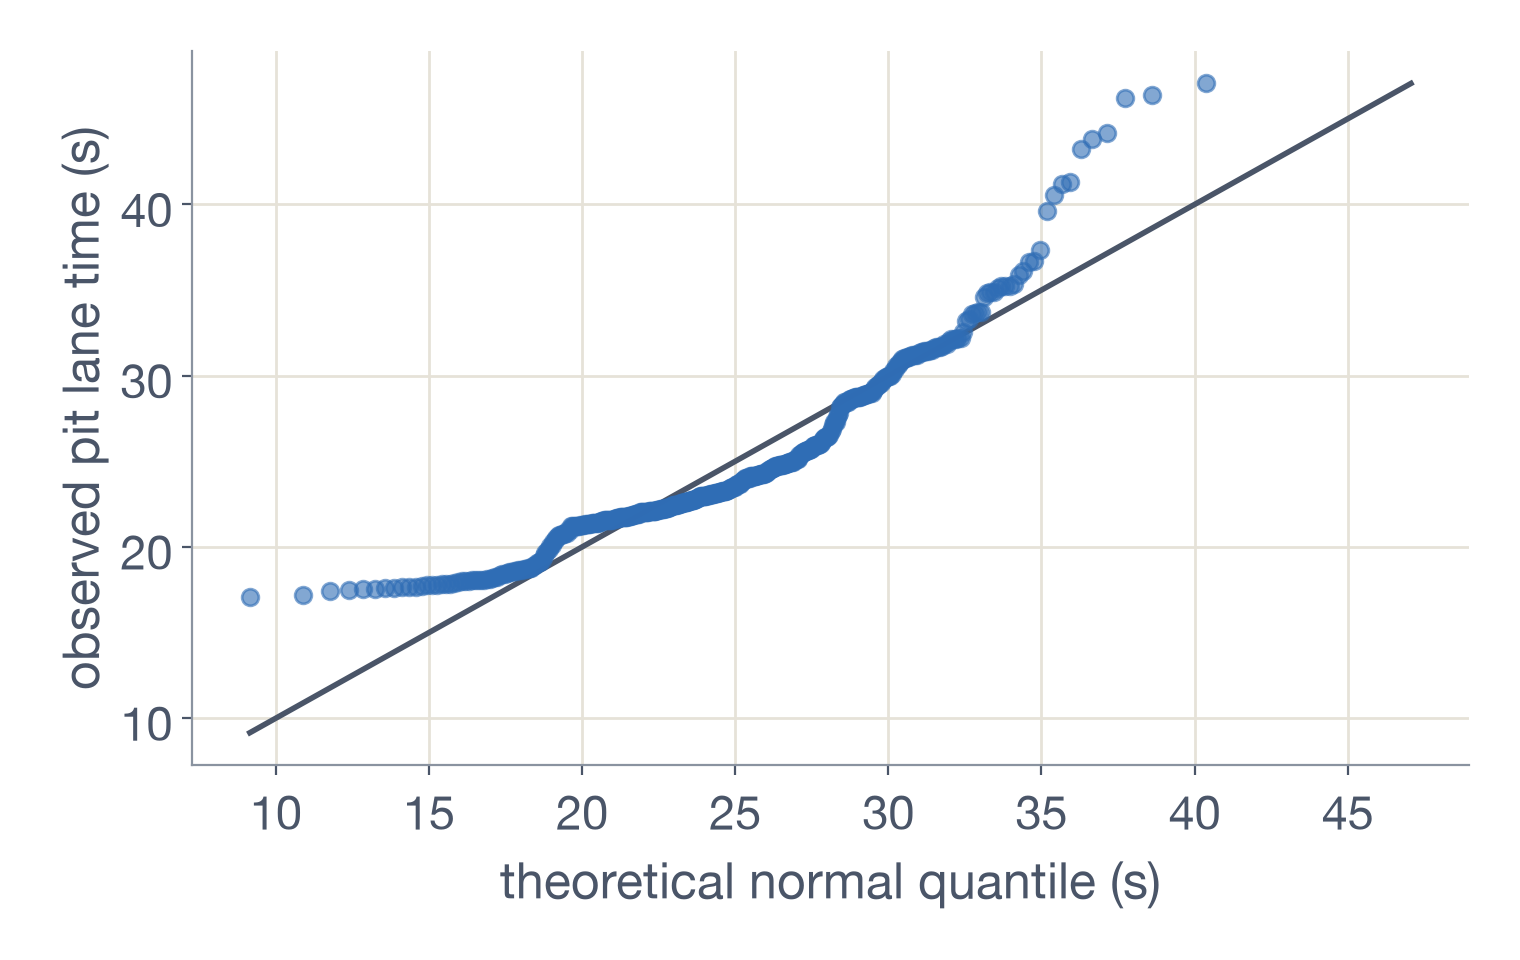

ch8_starts_linear.png


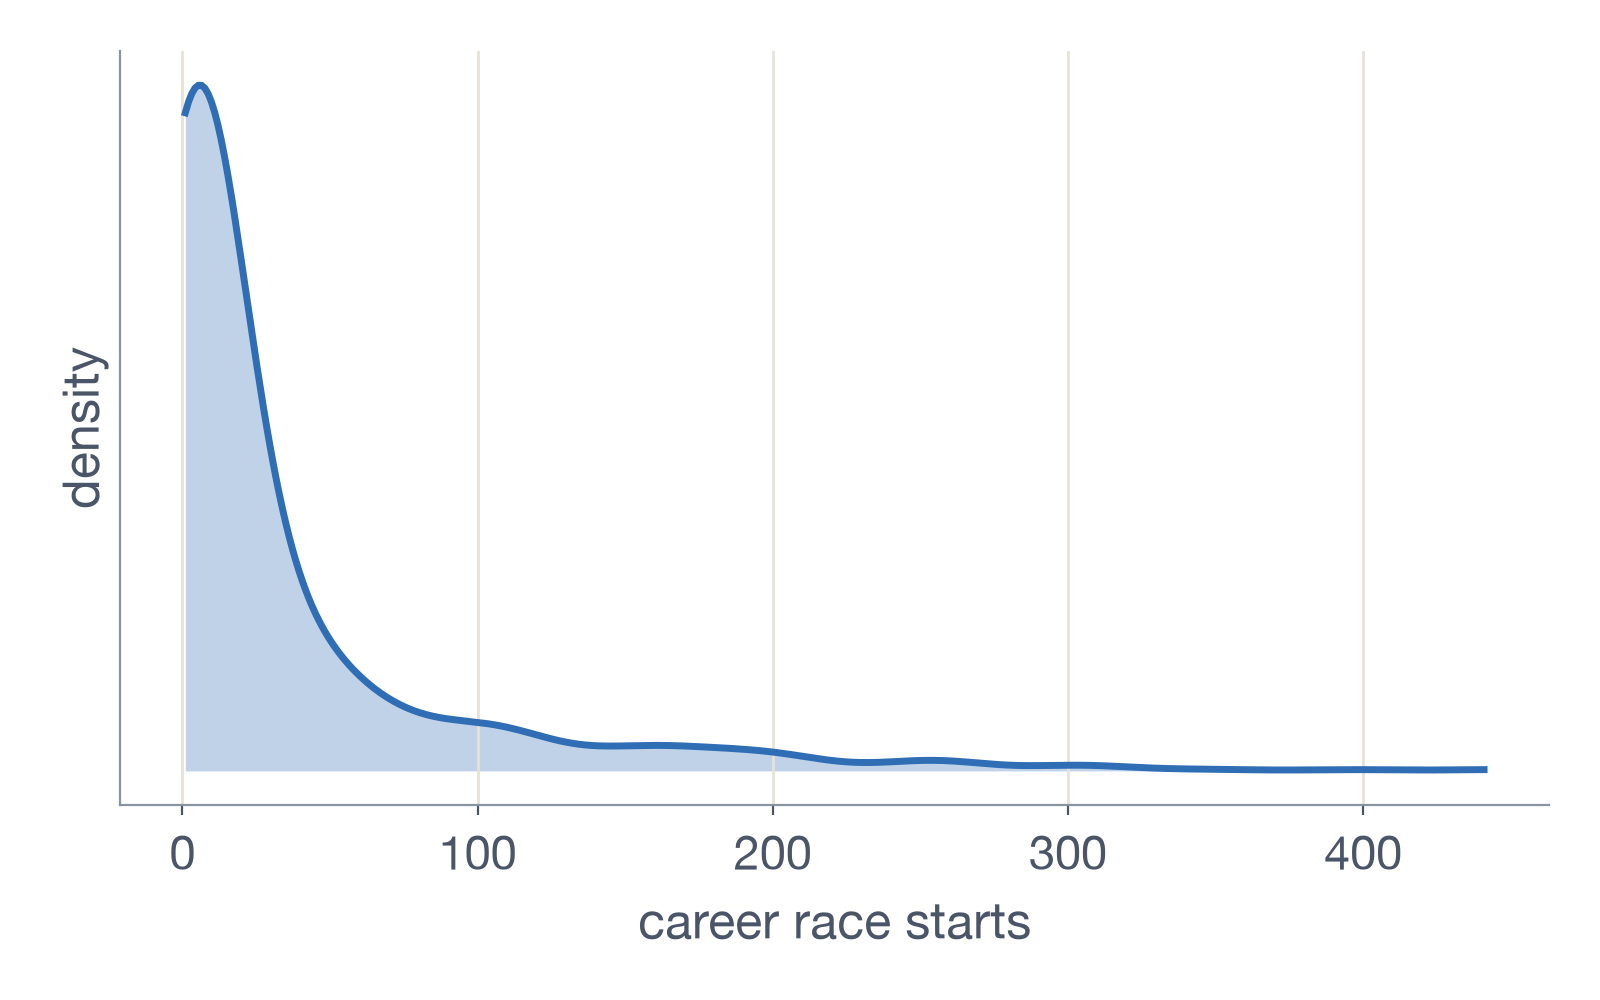

ch8_starts_log.png


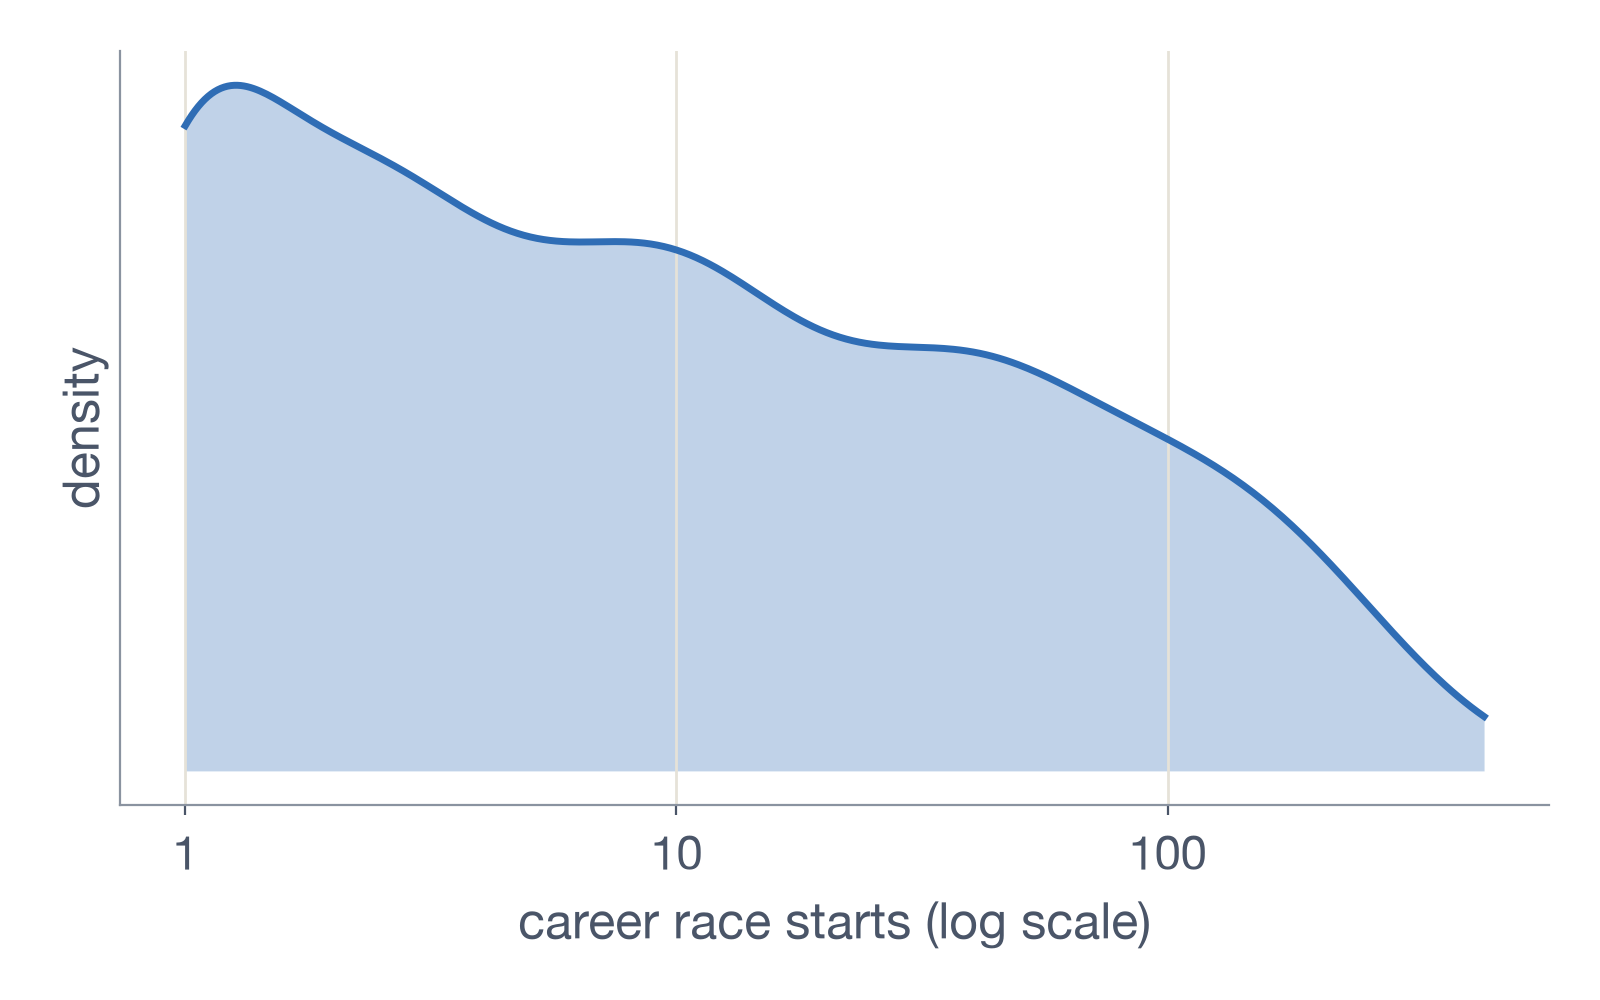

ch9_boxplots.png


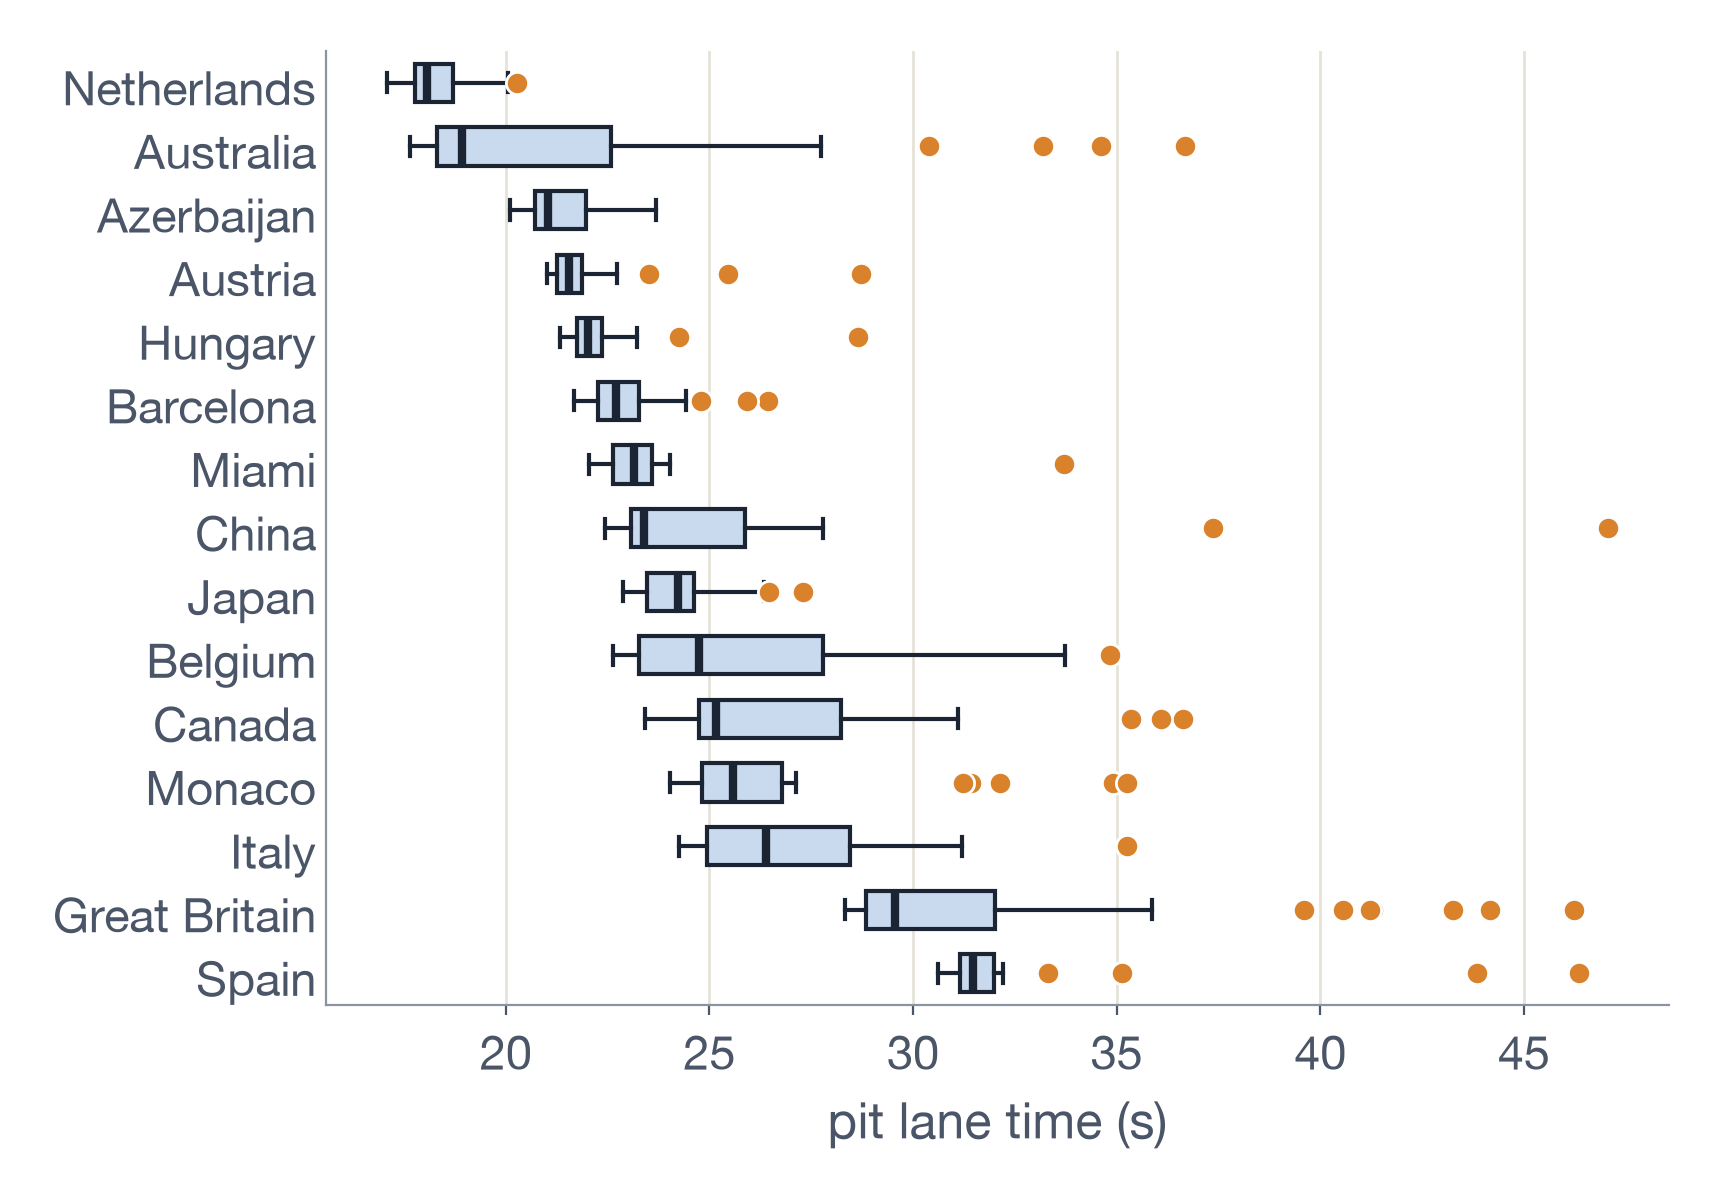

ch9_errorbars.png


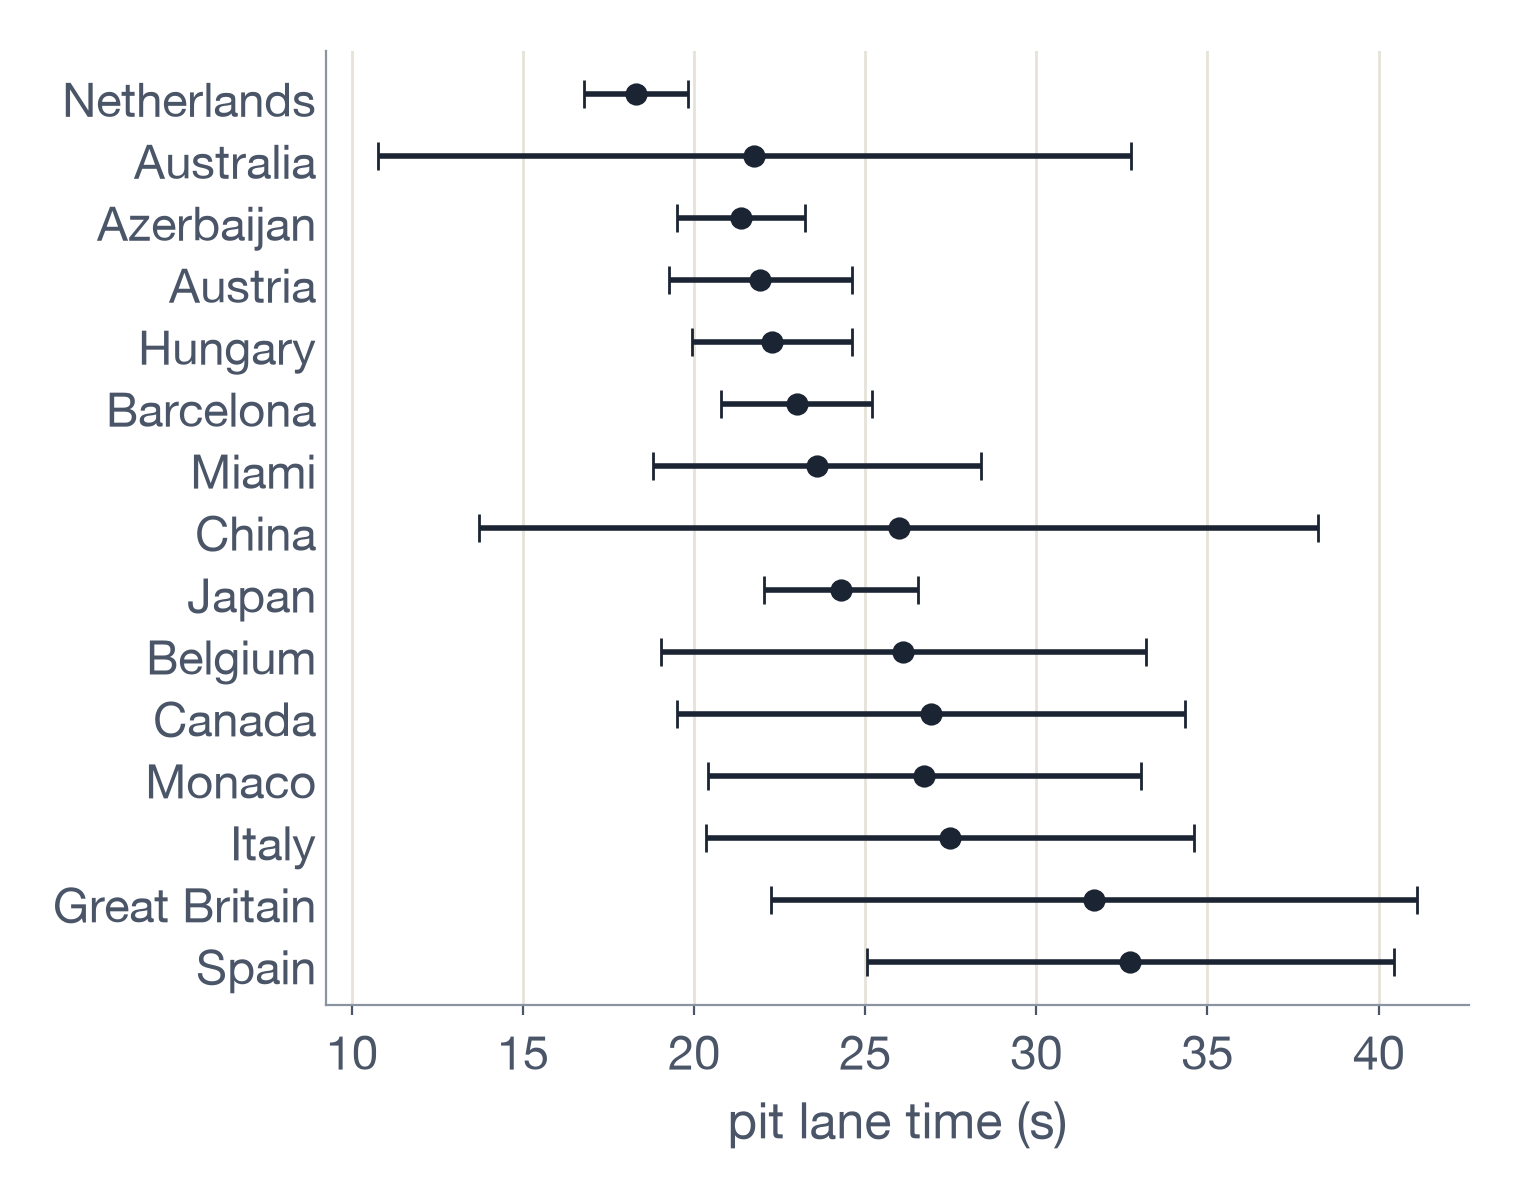

ch9_points_jitter.png


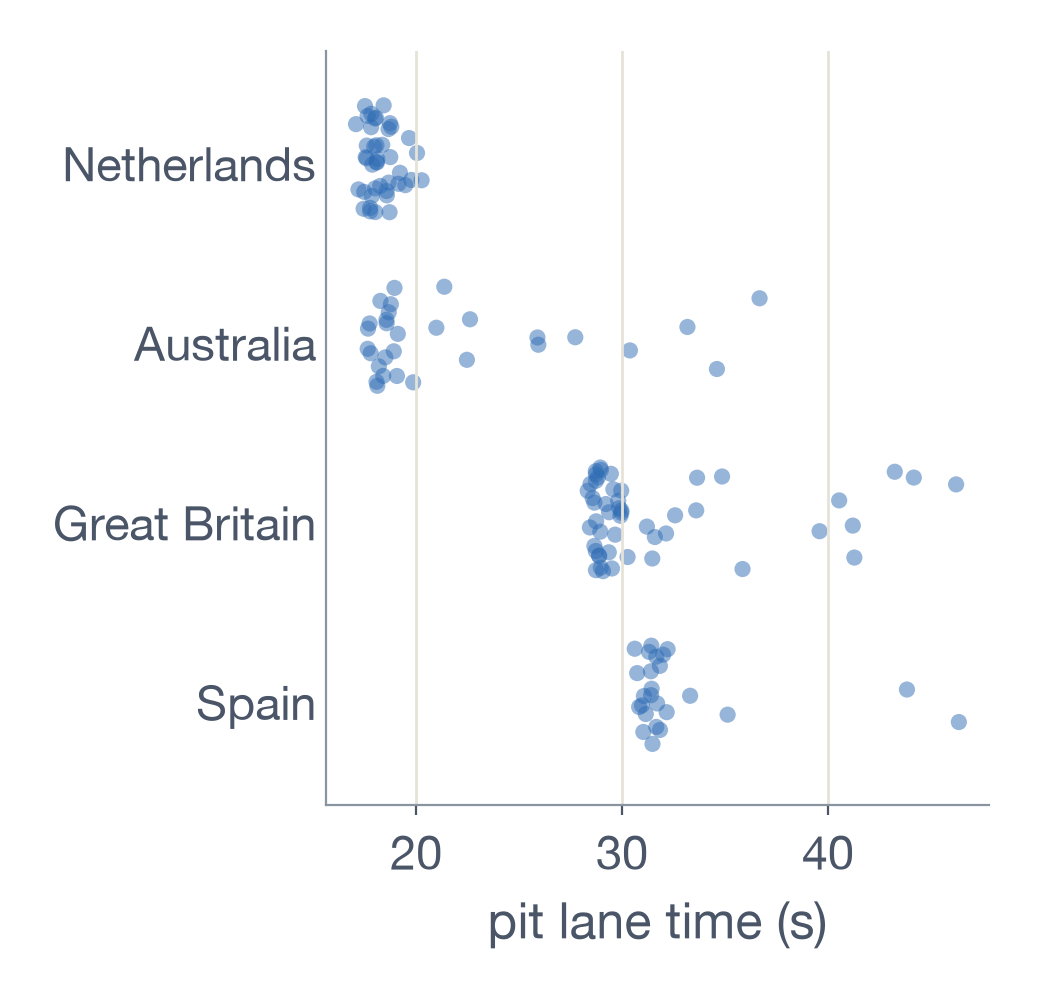

ch9_points_sina.png


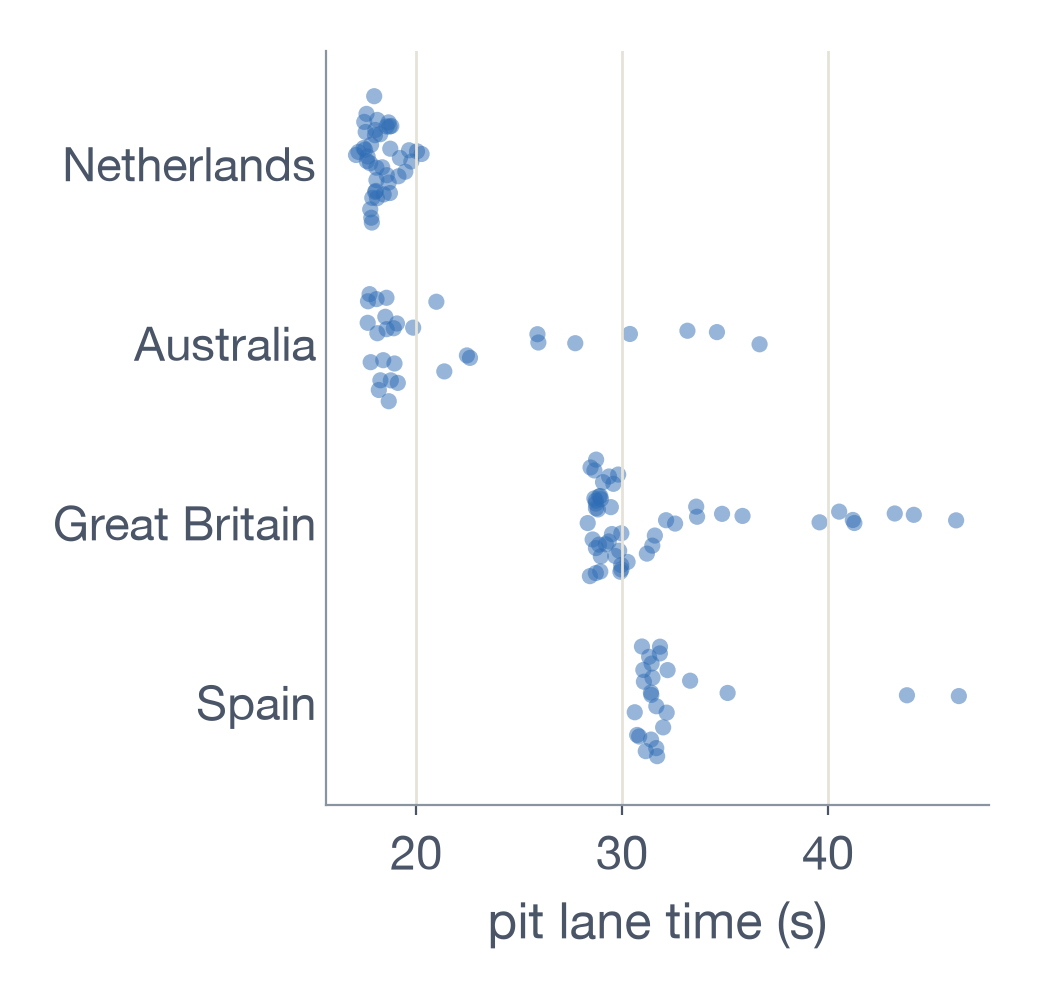

ch9_points_strip.png


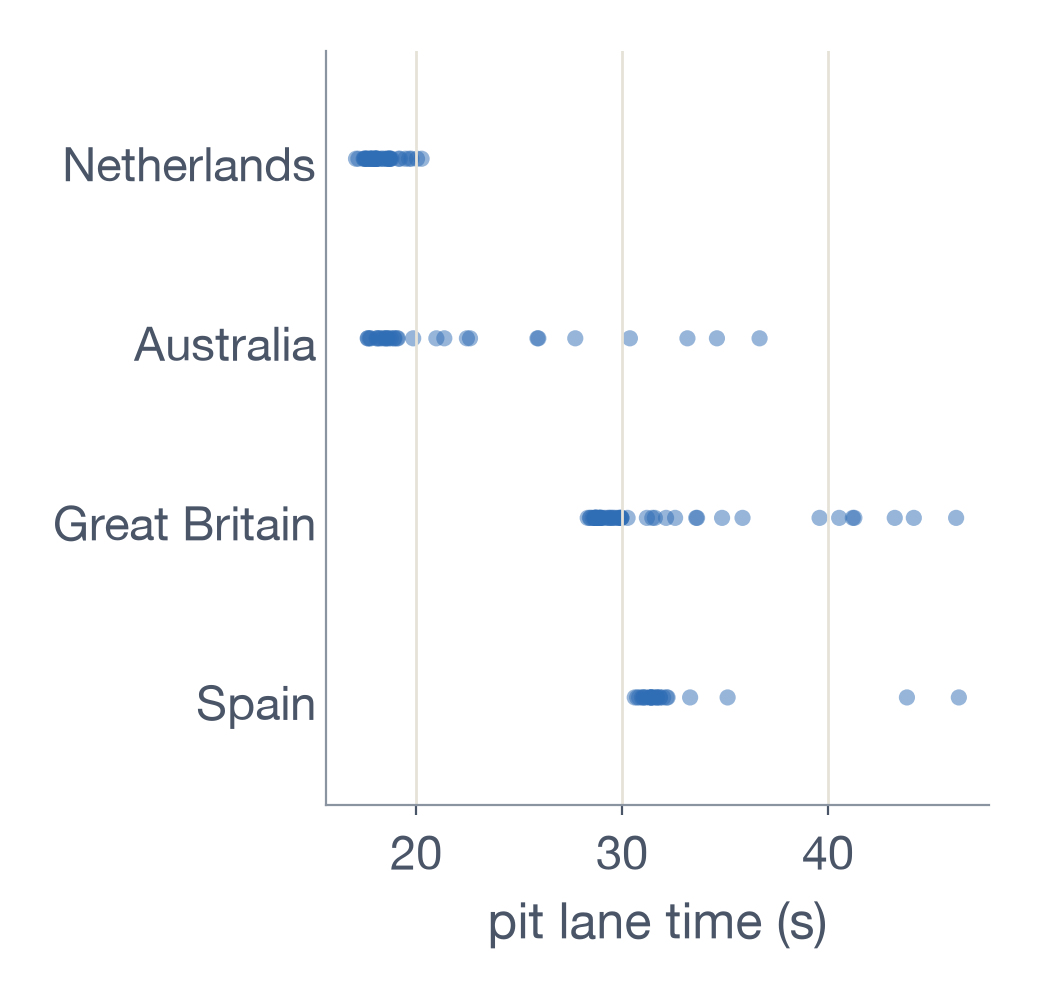

ch9_ridgeline_races.png


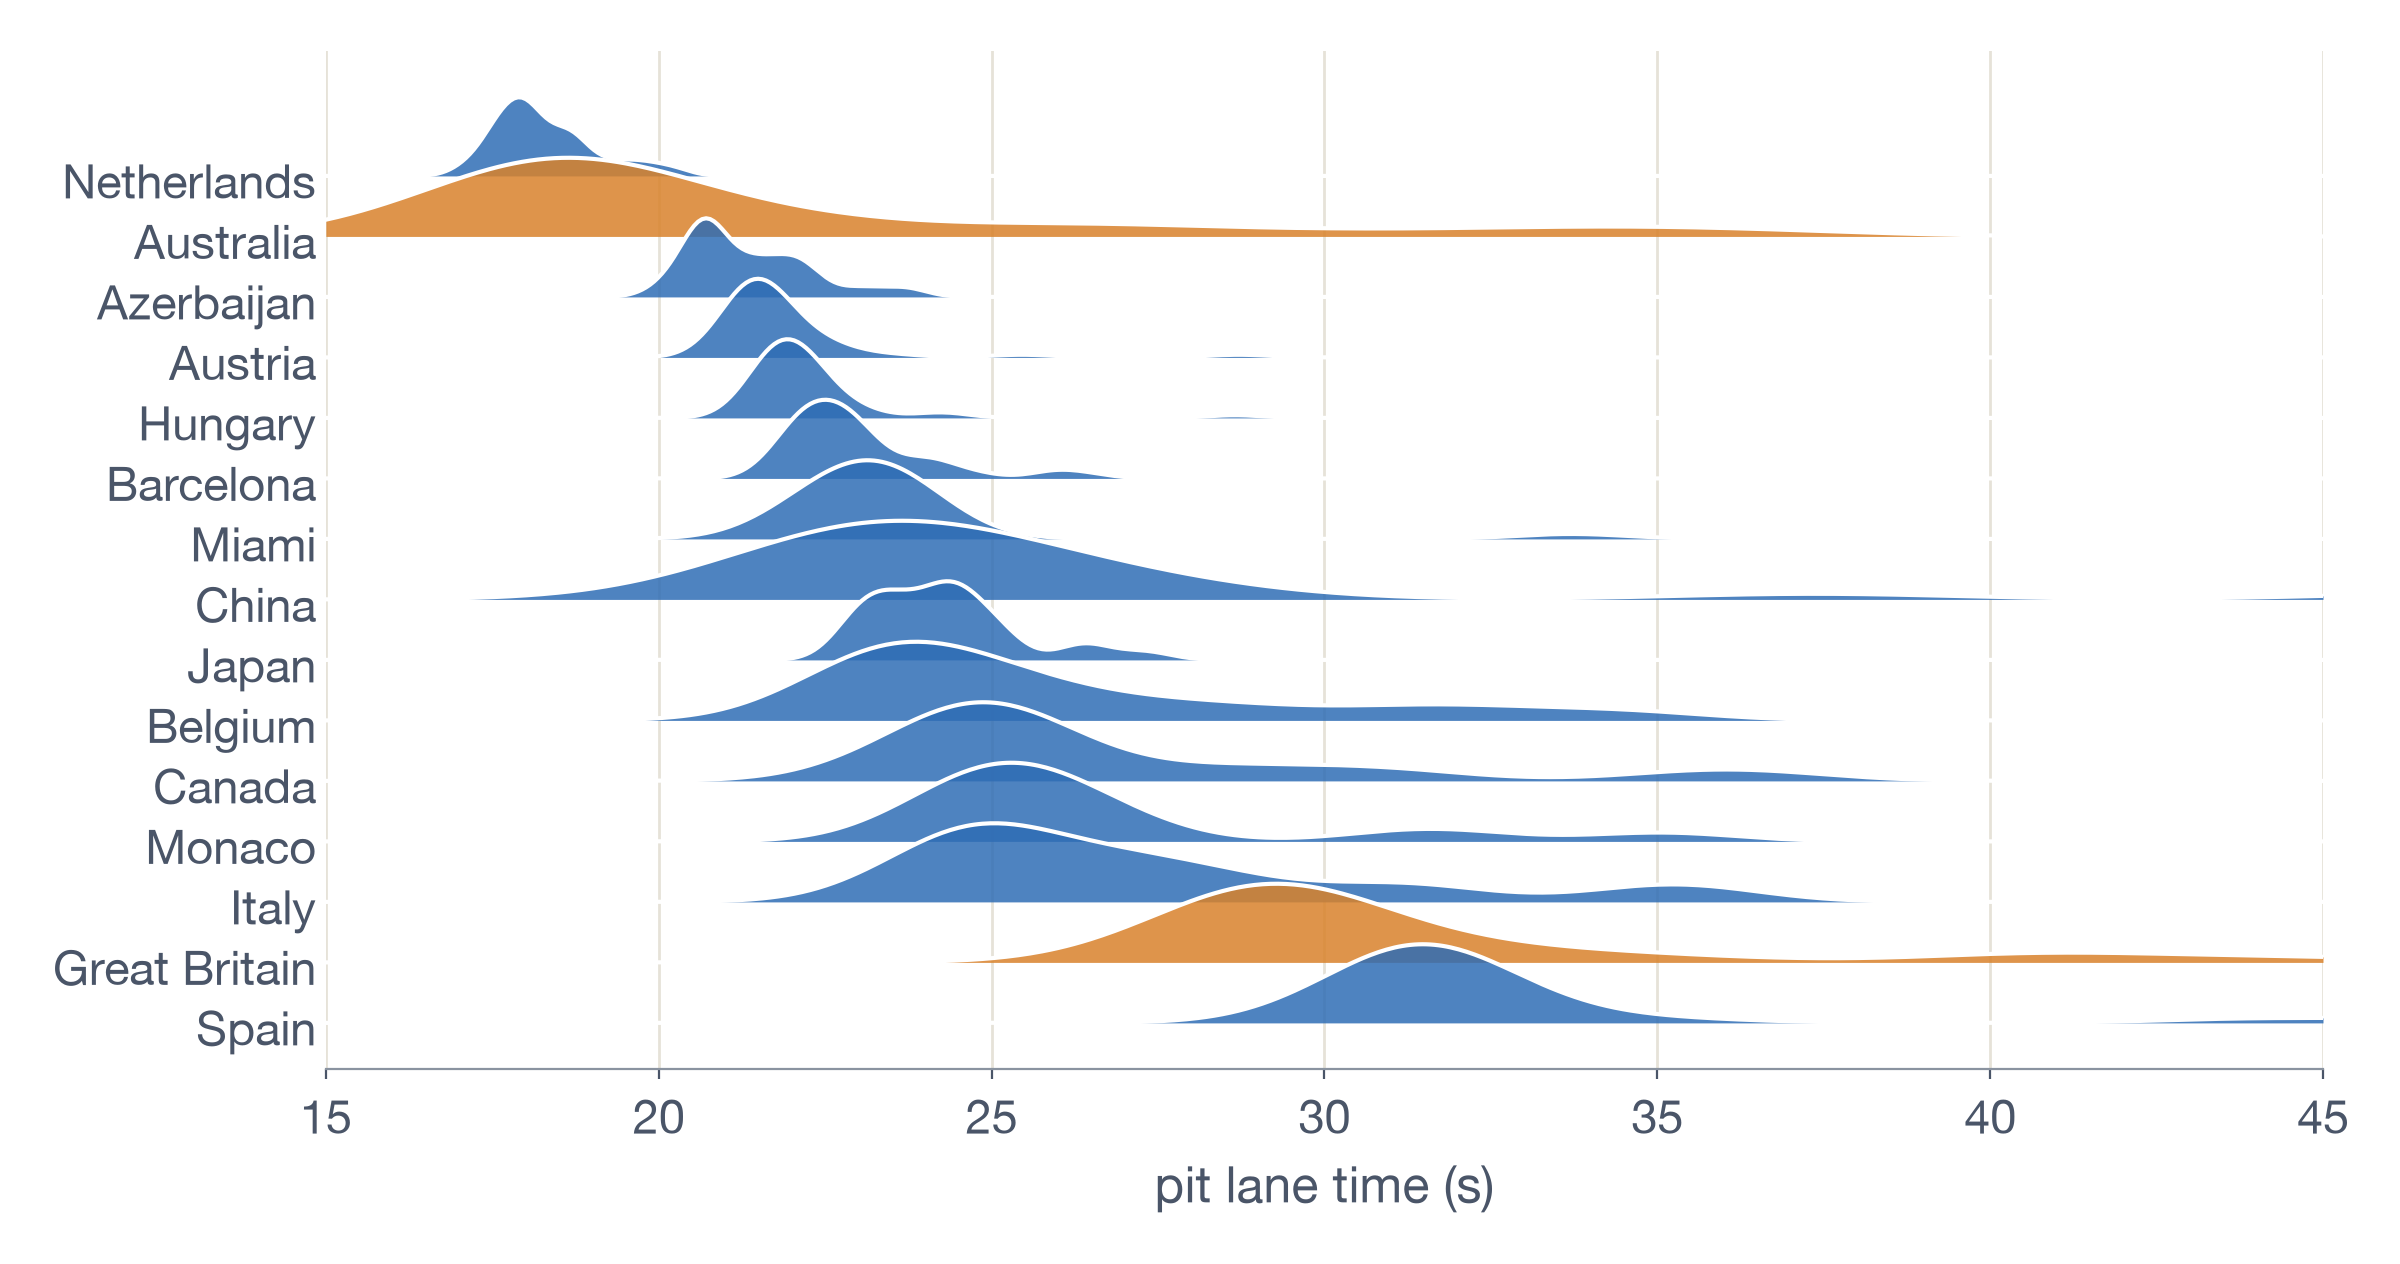

ch9_ridgeline_years.png


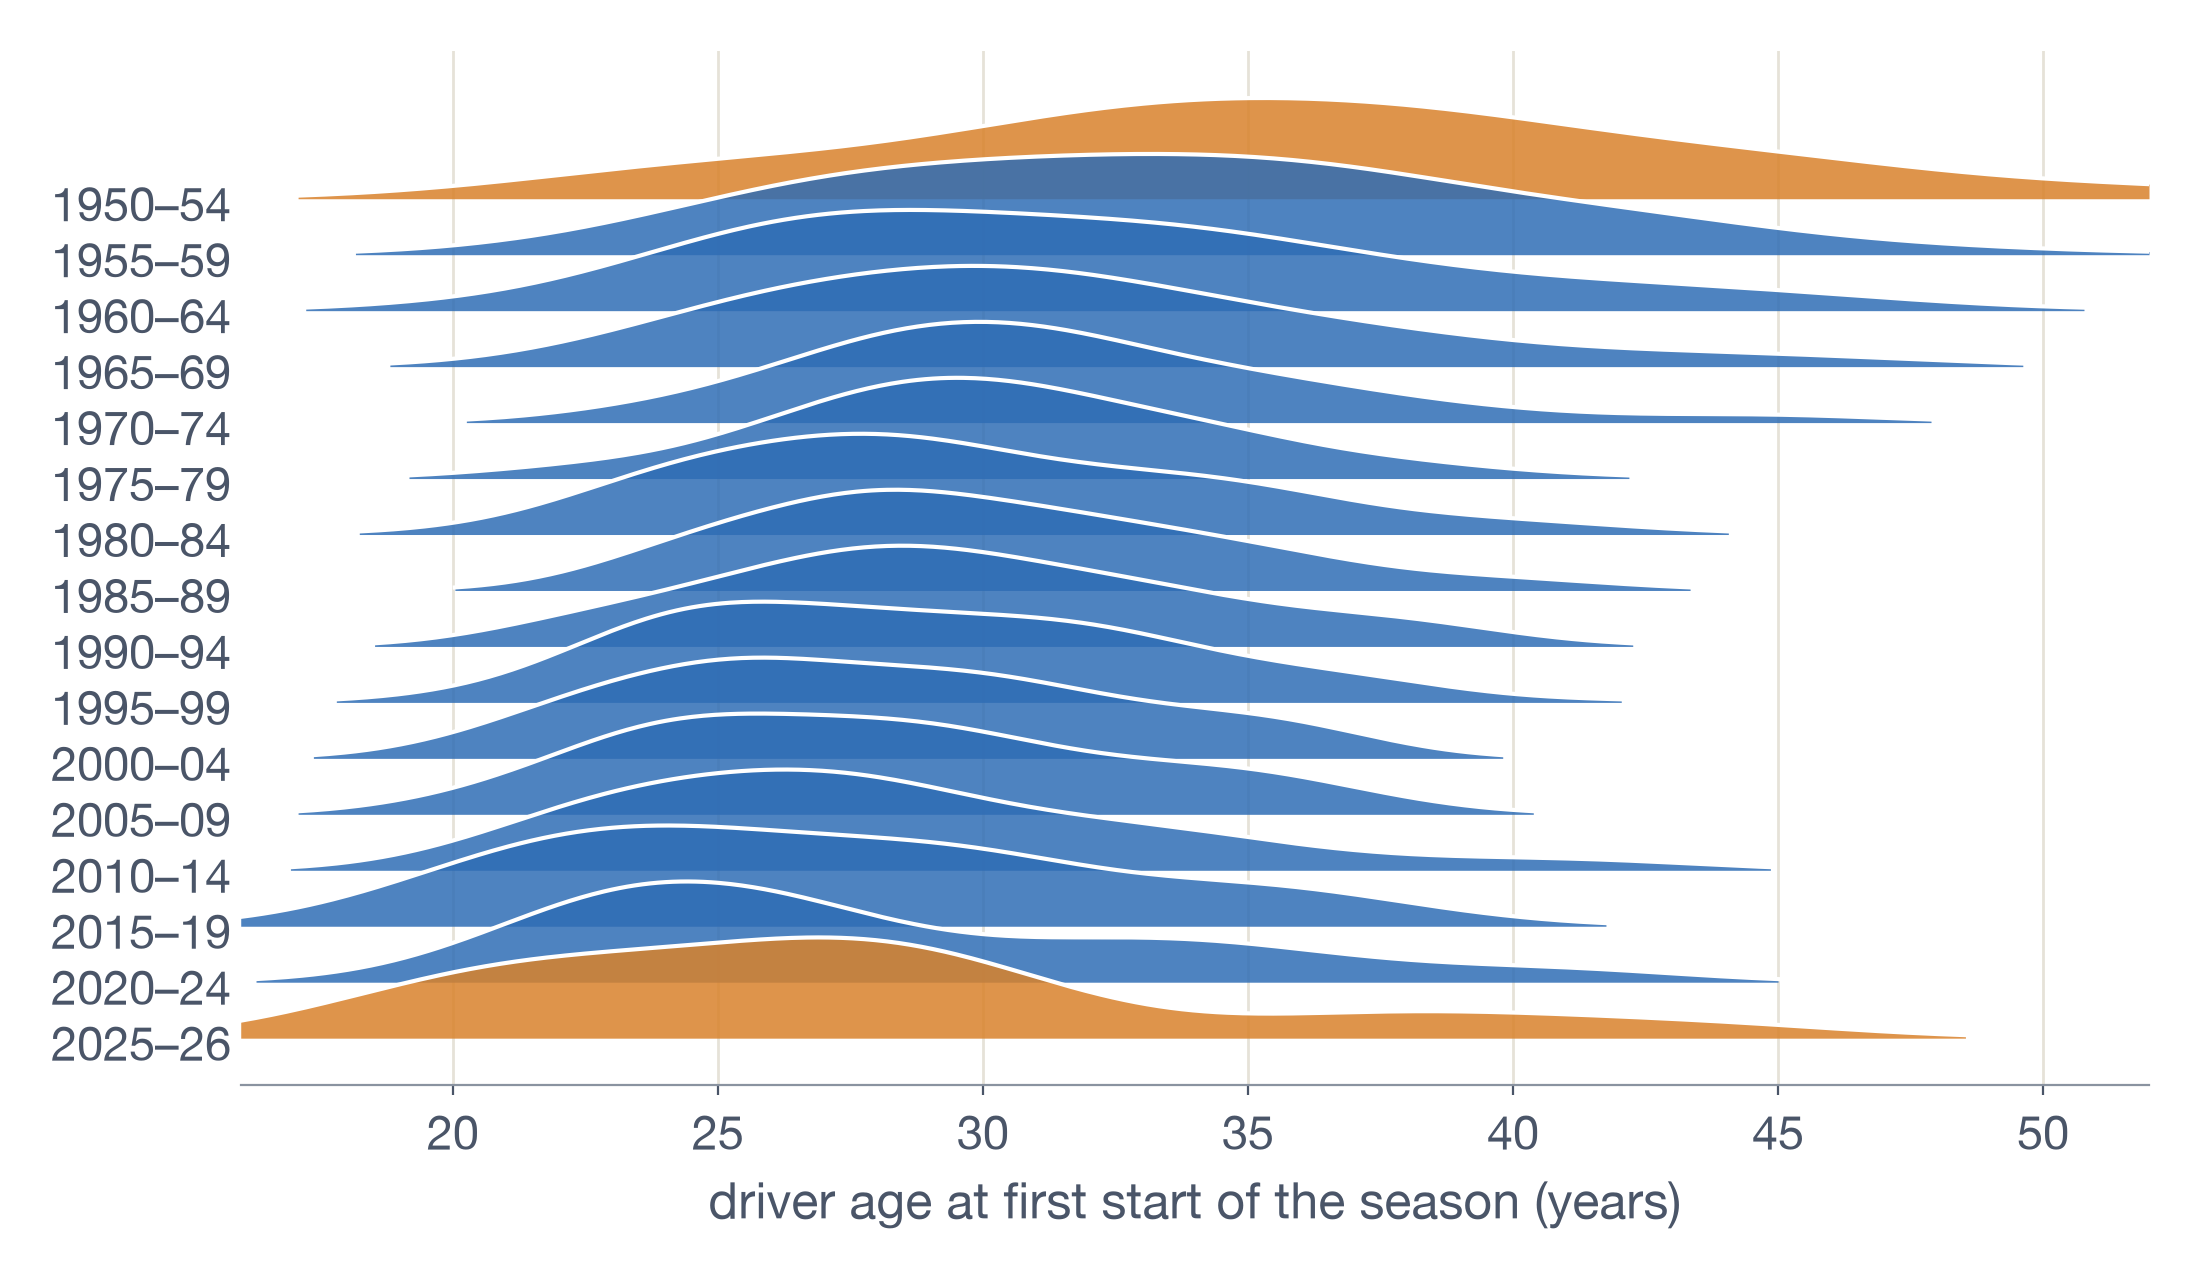

ch9_violins.png


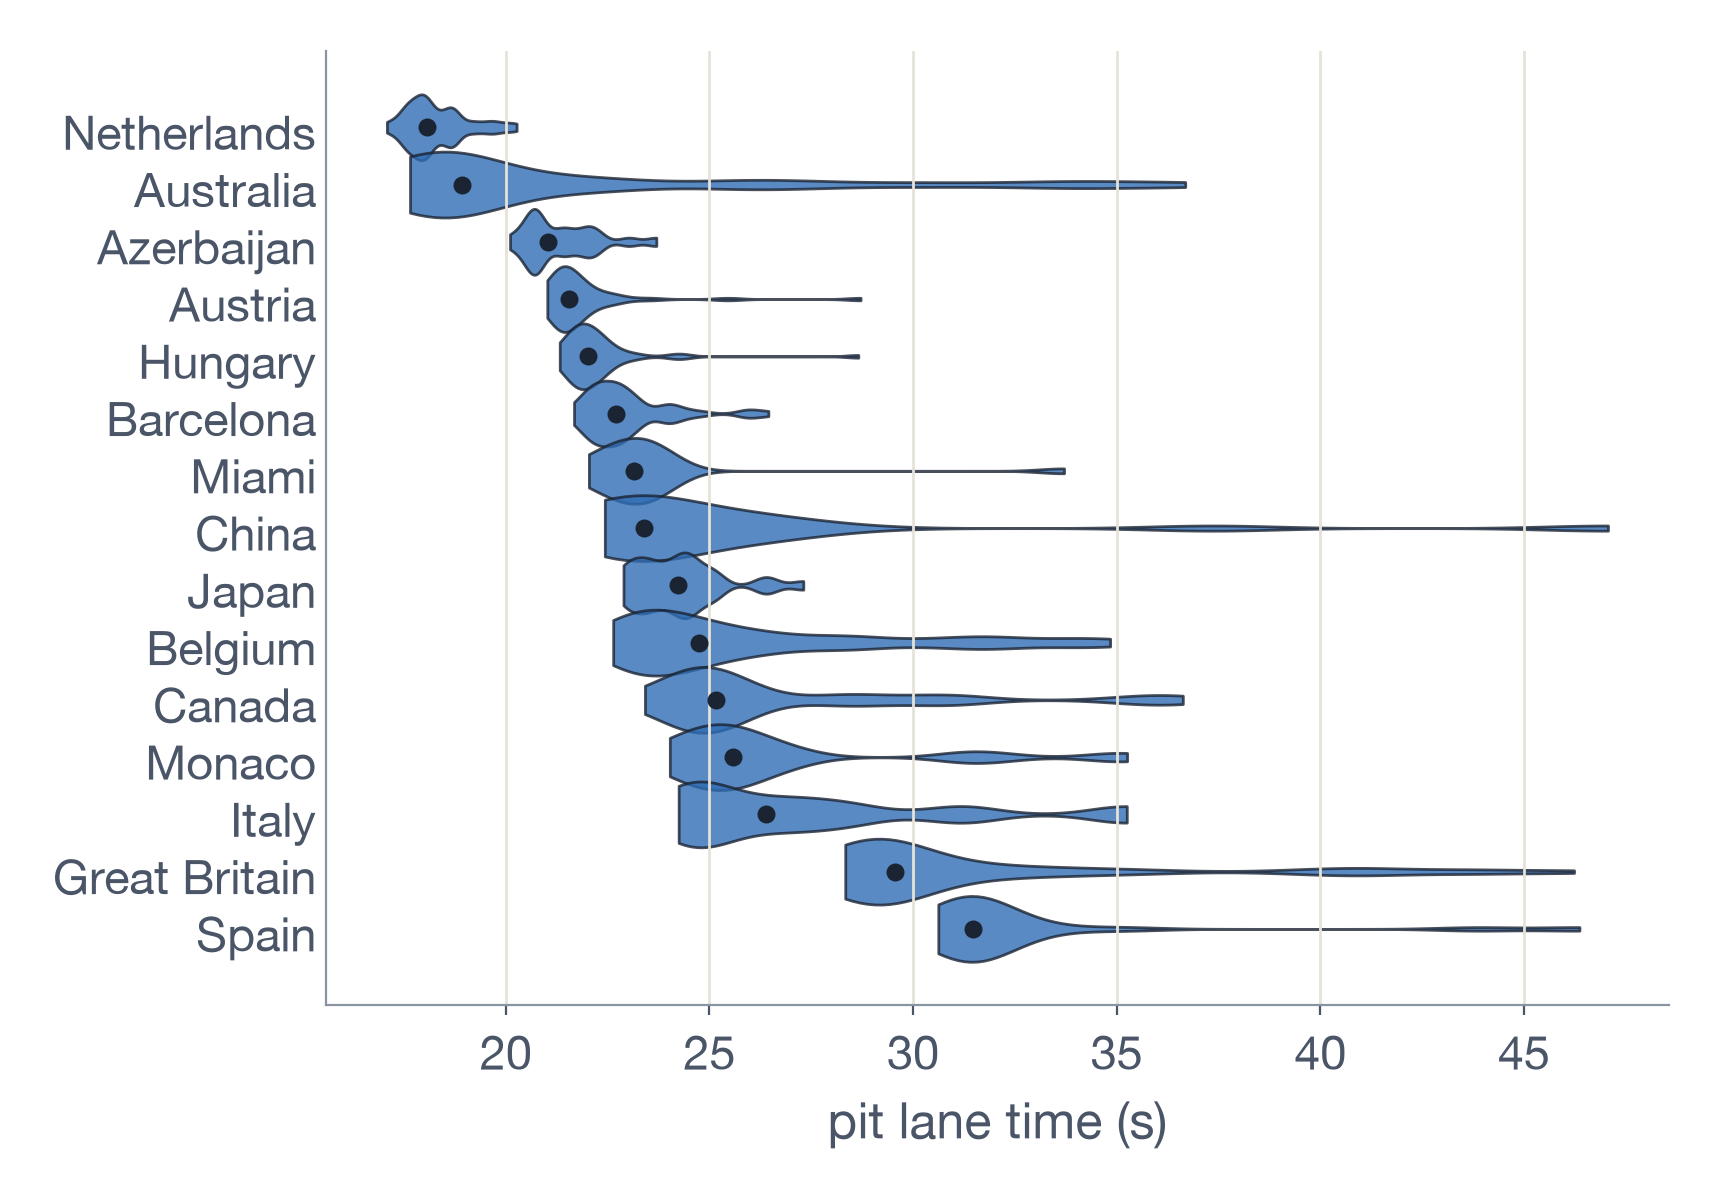

In [6]:
from IPython.display import Image, display
for p in sorted(OUT.glob("ch*.png")):
    print(p.name); display(Image(filename=p, width=700))